# Carbon Emission Data Cleaning and EDA

This notebook loads the supplied data, checks its quality, explores important patterns, and creates a separate model-ready CSV. It does not train models. Use the separate regression-model notebook for regression modelling.

## What this notebook does

1. Loads and audits the raw data.
2. Explores carbon-emission patterns with charts and grouped summaries.
3. Cleans values needed for modelling.
4. Converts multi-value fields into separate 0/1 columns.
5. One-hot encodes ordinary categorical columns.
6. Saves the model-ready CSV.

Next step: open the separate regression-model notebook after this notebook runs successfully.

In [10]:
# Run this once if your environment does not already have the packages.
# %pip install pandas numpy matplotlib seaborn scikit-learn

from pathlib import Path
import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


sns.set_theme(style='whitegrid')
RANDOM_STATE = 42
RAW_FILE = Path('Carbon Emission - LMS.csv')
MODEL_READY_FILE = Path('Carbon Emission - LMS Model Ready.csv')

## 1. Load and audit the raw data

This checks the shape, data types, missing values, and a small sample before we make any changes.

In [11]:
df = pd.read_csv(RAW_FILE)
print(f'Rows: {df.shape[0]:,} | Columns: {df.shape[1]}')
display(df.head())
display(pd.DataFrame({'data_type': df.dtypes.astype(str), 'missing_values': df.isna().sum(), 'unique_values': df.nunique()}))

Rows: 10,000 | Columns: 20


,Body Type,Sex,Diet,How Often Shower,Heating Energy Source,Transport,Vehicle Type,Social Activity,Monthly Grocery Bill,Frequency of Traveling by Air,Vehicle Monthly Distance Km,Waste Bag Size,Waste Bag Weekly Count,How Long TV PC Daily Hour,How Many New Clothes Monthly,How Long Internet Daily Hour,Energy efficiency,Recycling,Cooking_With,CarbonEmission
0,overweight,female,pescatarian,daily,coal,public,NaN,often,230,frequently,210,large,4,7,26,1,No,['Metal'],"['Stove', 'Oven']",2238
1,obese,female,vegetarian,less frequently,natural gas,walk/bicycle,NaN,often,114,rarely,9,extra large,3,9,38,5,No,['Metal'],"['Stove', 'Microwave']",1892
2,overweight,male,omnivore,more frequently,wood,private,petrol,never,138,never,2472,small,1,14,47,6,Sometimes,['Metal'],"['Oven', 'Microwave']",2595
3,overweight,male,omnivore,twice a day,wood,walk/bicycle,NaN,sometimes,157,rarely,74,medium,3,20,5,7,Sometimes,"['Paper', 'Plastic', 'Glass', 'Metal']","['Microwave', 'Grill', 'Airfryer']",1074
4,obese,female,vegetarian,daily,coal,private,diesel,often,266,very frequently,8457,large,1,3,5,6,Yes,['Paper'],['Oven'],4743


,data_type,missing_values,unique_values
Body Type,str,0,4
Sex,str,0,2
Diet,str,0,4
How Often Shower,str,0,4
Heating Energy Source,str,0,4
Transport,str,0,3
Vehicle Type,str,6721,5
Social Activity,str,0,3
Monthly Grocery Bill,int64,0,250
Frequency of Traveling by Air,str,0,4


## 2. Quick exploratory analysis

The charts below help you understand the prediction target and compare average emissions across important lifestyle categories.

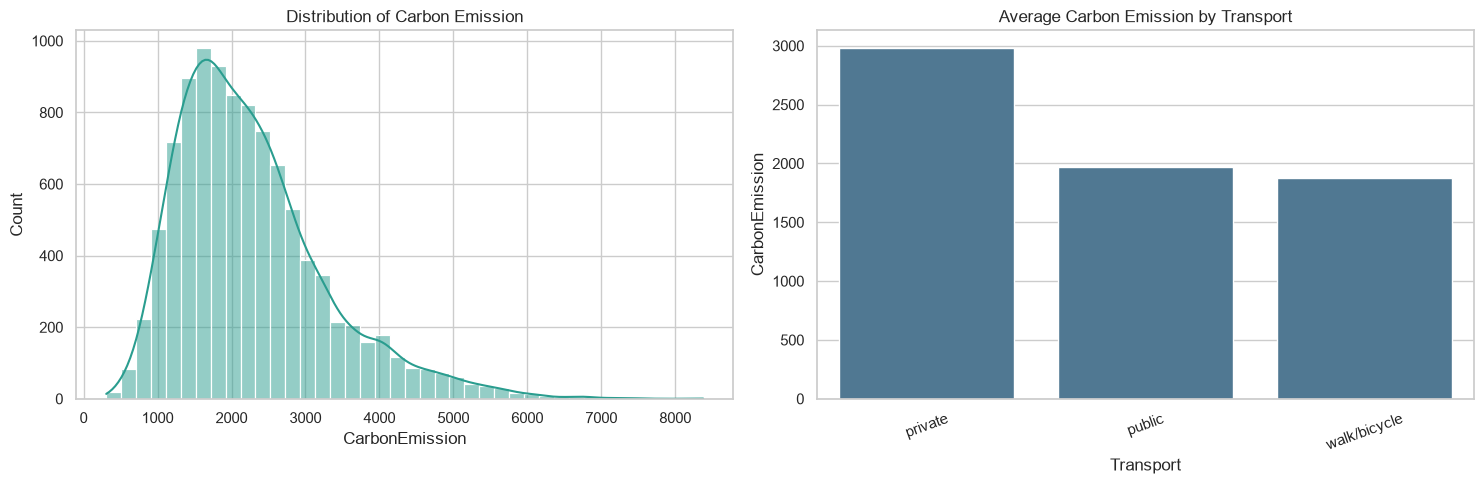


Average emissions by Diet:


,CarbonEmission
Diet,
omnivore,2391.98
pescatarian,2251.84
vegetarian,2216.81
vegan,2215.76



Average emissions by Heating Energy Source:


,CarbonEmission
Heating Energy Source,
coal,2495.06
wood,2296.82
natural gas,2248.12
electricity,2039.38



Average emissions by Frequency of Traveling by Air:


,CarbonEmission
Frequency of Traveling by Air,
very frequently,3026.46
frequently,2362.87
rarely,1945.87
never,1716.34



Average emissions by Energy efficiency:


,CarbonEmission
Energy efficiency,
No,2286.66
Sometimes,2269.15
Yes,2252.14


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.histplot(data=df, x='CarbonEmission', bins=40, kde=True, ax=axes[0], color='#2a9d8f')
axes[0].set_title('Distribution of Carbon Emission')

transport_means = df.groupby('Transport', as_index=False)['CarbonEmission'].mean().sort_values('CarbonEmission', ascending=False)
sns.barplot(data=transport_means, x='Transport', y='CarbonEmission', ax=axes[1], color='#457b9d')
axes[1].set_title('Average Carbon Emission by Transport')
axes[1].tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()

for column in ['Diet', 'Heating Energy Source', 'Frequency of Traveling by Air', 'Energy efficiency']:
    print(f'\nAverage emissions by {column}:')
    display(df.groupby(column)['CarbonEmission'].mean().sort_values(ascending=False).round(2).to_frame())

## 3. Create a model-ready dataset

`Vehicle Type` is blank for records without a private vehicle. A blank is meaningful here, so it becomes `No vehicle` rather than being guessed or removed.

`Recycling` and `Cooking_With` contain lists in text form. We convert each possible item into its own 0/1 column. All remaining categories are one-hot encoded. This creates numeric input columns that regression models can use directly. No outliers are automatically deleted; they should be examined and justified in your report before removal.

In [13]:
clean_df = df.copy()

# Clean text spacing and give blank vehicle types a meaningful label.
text_columns = clean_df.select_dtypes(include='object').columns
clean_df[text_columns] = clean_df[text_columns].apply(lambda col: col.str.strip())
clean_df['Vehicle Type'] = clean_df['Vehicle Type'].replace('', np.nan).fillna('No vehicle')

def parse_list(value):
    """Safely convert strings such as ['Paper', 'Glass'] into Python lists."""
    if isinstance(value, list):
        return value
    try:
        return ast.literal_eval(value)
    except (ValueError, SyntaxError, TypeError):
        return []

def expand_multivalue_column(data, column, prefix):
    lists = data[column].apply(parse_list)
    all_items = sorted({item for row in lists for item in row})
    expanded = pd.DataFrame(
        {f'{prefix}{item}': lists.apply(lambda row: int(item in row)) for item in all_items},
        index=data.index,
    )
    return expanded

recycling_features = expand_multivalue_column(clean_df, 'Recycling', 'Recycling_')
cooking_features = expand_multivalue_column(clean_df, 'Cooking_With', 'Cooking_')
clean_df = clean_df.drop(columns=['Recycling', 'Cooking_With'])
clean_df = pd.concat([clean_df, recycling_features, cooking_features], axis=1)

target_column = 'CarbonEmission'
categorical_columns = clean_df.select_dtypes(include='object').columns.tolist()
model_ready_df = pd.get_dummies(clean_df, columns=categorical_columns, dtype=int)
model_ready_df.to_csv(MODEL_READY_FILE, index=False)

print(f'Model-ready dataset saved to: {MODEL_READY_FILE.resolve()}')
print(f'Model-ready shape: {model_ready_df.shape}')
print(f'Missing values after preprocessing: {model_ready_df.isna().sum().sum()}')
display(model_ready_df.head())

C:\Users\DELL\AppData\Local\Temp\ipykernel_10648\1571927784.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_columns = clean_df.select_dtypes(include='object').columns
C:\Users\DELL\AppData\Local\Temp\ipykernel_10648\1571927784.py:32: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/use

Model-ready dataset saved to: C:\Users\DELL\Desktop\PROJECT\Carbon Emission - LMS Model Ready.csv
Model-ready shape: (10000, 57)
Missing values after preprocessing: 0


,Monthly Grocery Bill,Vehicle Monthly Distance Km,Waste Bag Weekly Count,How Long TV PC Daily Hour,How Many New Clothes Monthly,How Long Internet Daily Hour,CarbonEmission,Recycling_Glass,Recycling_Metal,Recycling_Paper,...,Frequency of Traveling by Air_never,Frequency of Traveling by Air_rarely,Frequency of Traveling by Air_very frequently,Waste Bag Size_extra large,Waste Bag Size_large,Waste Bag Size_medium,Waste Bag Size_small,Energy efficiency_No,Energy efficiency_Sometimes,Energy efficiency_Yes
0,230,210,4,7,26,1,2238,0,1,0,...,0,0,0,0,1,0,0,1,0,0
1,114,9,3,9,38,5,1892,0,1,0,...,0,1,0,1,0,0,0,1,0,0
2,138,2472,1,14,47,6,2595,0,1,0,...,1,0,0,0,0,0,1,0,1,0
3,157,74,3,20,5,7,1074,1,1,1,...,0,1,0,0,0,1,0,0,1,0
4,266,8457,1,3,5,6,4743,0,0,1,...,0,0,1,0,1,0,0,0,0,1


## Next step

After this notebook creates the model-ready CSV, open Carbon_Emission_Regression_Model.ipynb to train and compare regression models.